In [56]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os, sys
import pandas as pd
import networkx as nx
import datetime
import time
import random
import plotly.express as px
import seaborn as sns
import scipy.special as scispe
import seaborn as sns
import plotly.figure_factory as ff
import pickle
from IPython.display import clear_output
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import time
import shutil
import sklearn
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

from LIBS.network1_library import from_amatrix_to_edgelist
from LIBS.after_embedding_library import convert_polar_cartesian
from LIBS.hyperboloid_embedding_library import plot_Pdisk_embedding
from LIBS.kNHD_score_library import from_embedding_to_idxKNNmatrix,from_KNNmatrix_to_scores, two_nets_kNHD_score, coalescent_embedding_2D_fc
from LIBS.perturbatations import perturbation_disconnection_NT
from LIBS.networks_class_definition_1 import networks
import LIBS.networks_class_definition_1 as ncd
from LIBS.utils import *
from LIBS.embedding_library_martin import rotation_similarity_embedding
from LIBS.HyperboloidEmbedding import plot_Pdisk_embedding,plot_Pdisk_embedding_n

import mercator

### Objective: compare computation complexity of embedding Original and Perturbed networks with Coalescent and Mercator methods

## INIT

#### Original graph: WS


In [57]:
model = "WattsStrogatz"
N = 150
kl = 20 #k lattice
pr = 0.1 #p rewiring

G = nx.watts_strogatz_graph(N,kl,pr)

degrees = np.array(list(nx.degree(G)))[:,1]
clusterings = np.array([val for val in nx.clustering(G).values()])

A = nx.to_numpy_array(G)
edgelist = from_amatrix_to_edgelist(A)
edgelist = edgelist[np.where(edgelist[:,2]==1)[0],:].astype('int')

edgelist_path = '/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/OUTPUT-MEDIA-test-Mercator/Data/edgelist_%s_O' %model
np.savetxt(edgelist_path+'.txt', edgelist)

#### Embedding original graph

In [58]:
# Embedding parameters COALESCENT

embedding_parameters_dict = {
'preweight':True, 
'laplacian':False, 
'dim_red_method':'ISOMAP', 
'eigen_solver':'dense', 
'n_neighbors':'auto', 
'equi_adj':True, 
'eta_r':1,
'beta_r':0.8,
'order_r':'auto',
'weight_r':None,
'radius_def':True,
'order_sign':1,
'max_r_margin':1e-5,
}
embedding_parameters = np.array(list(embedding_parameters_dict.values()))

output_folder_C = 'OUTPUT-MEDIA-test-Mercator/output_iso'
media_folder_C = 'OUTPUT-MEDIA-test-Mercator/media_iso'

In [59]:
# Embedding parameters MERCATOR

output_folder_M = 'OUTPUT-MEDIA-test-Mercator/output_Mercator'
media_folder_M = 'OUTPUT-MEDIA-test-Mercator/media_Mercator'

#### Other parameters

In [60]:
# number of NN to take into account
k = 10

# perturbation magnitude 20-40-60-80/100
mag_arr = np.array([0, 5/100, 20/100, 40/100, 60/100, 80/100])
mag = mag_arr[2]
mag

0.2

### COMPUTE EMBEDDING O+P TIME 

#### Embed Original graph G with Coalescent
- Compute time t1_C
#### Embed Original graph G with Mercator
- Compute time t1_M

In [61]:
colormap = 'tab20' 
norm = Normalize(vmin=0, vmax=N)
sm = ScalarMappable(norm=norm, cmap=colormap)
#colors = sm.to_rgba(x_t[:,i])
colors = [plt.cm.get_cmap(colormap)(norm(value))[:3] for value in range(N)]
colors = [plt.cm.colors.rgb2hex(color) for color in colors]

In [62]:
t0 = time.time()

dict_xy = coalescent_embedding_2D_fc(G, *embedding_parameters, res_dict=True, normalize_radius=True)
 
t1_C = time.time()-t0

xy_coalescent = np.array(list(dict_xy[0].values()))

Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()


R =  0.9999975955140467


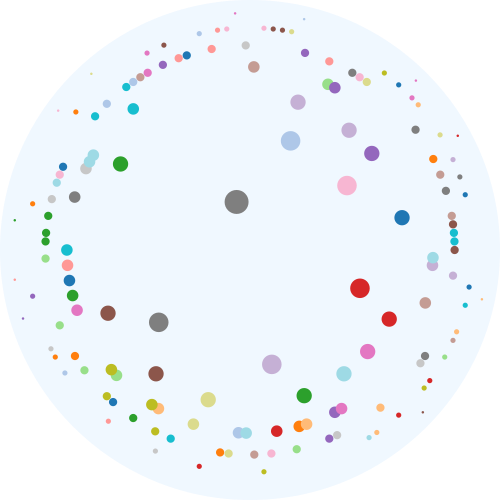

In [63]:
plot_Pdisk_embedding_n(xy_coalescent, node_colors=colors, sizes=np.array(N*[0.1]))


In [64]:
t0 = time.time()

mercator.embed(edgelist_path+'.txt', output_name=edgelist_path, fast_mode=True)

t1_M = time.time()-t0

shutil.copyfile(edgelist_path+'.inf_log', edgelist_path+'.inf_log'+'.txt')
shutil.copyfile(edgelist_path+'.inf_coord',edgelist_path+'.inf_coord'+'.txt') 
coords_tr = np.loadtxt(edgelist_path+'.inf_coord'+'.txt', usecols=(2,3))

#r_norm = coords_tr[:,1]/(np.max(coords_tr[:,1])+0.2) # normalise radius, +0.2 as it is done in the coalescent embedding alg
r = coords_tr[:,1]
r_norm = (r-np.min(r))/(np.max(r)-np.min(r))
x, y = convert_polar_cartesian(r_norm,coords_tr[:,0])
xy_mercator = np.column_stack((x,y))

R =  1.0


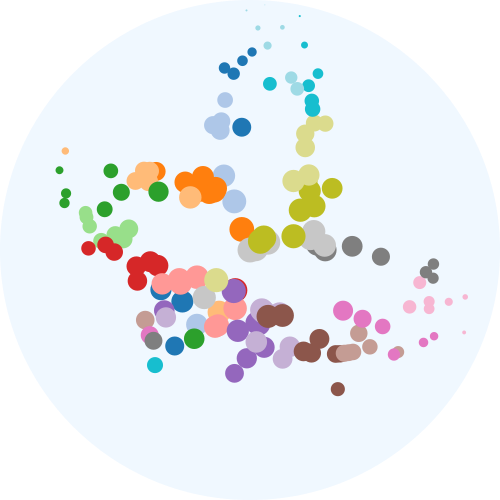

In [65]:
plot_Pdisk_embedding_n(xy_mercator, node_colors=colors, sizes=np.array(N*[0.1]))

In [66]:
t0 = time.time()

mercator.embed(edgelist_path+'.txt', output_name=edgelist_path)

t1_M = time.time()-t0

shutil.copyfile(edgelist_path+'.inf_log', edgelist_path+'.inf_log'+'.txt')
shutil.copyfile(edgelist_path+'.inf_coord',edgelist_path+'.inf_coord'+'.txt') 
coords_tr = np.loadtxt(edgelist_path+'.inf_coord'+'.txt', usecols=(2,3))

#r_norm = coords_tr[:,1]/(np.max(coords_tr[:,1])+0.2) # normalise radius, +0.2 as it is done in the coalescent embedding alg
r = coords_tr[:,1]
r_norm = (r-np.min(r))/(np.max(r)-np.min(r))
x, y = convert_polar_cartesian(r_norm,coords_tr[:,0])
xy_mercator = np.column_stack((x,y))

R =  1.0


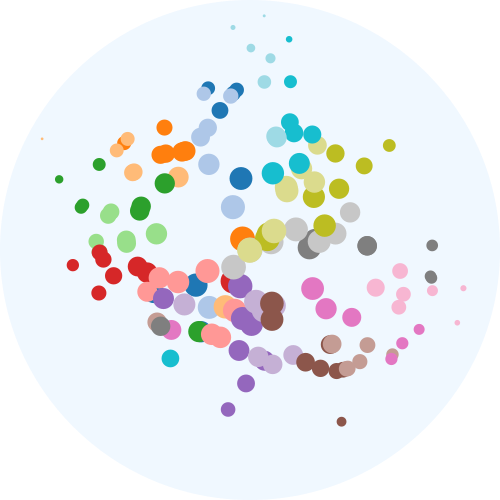

In [67]:
plot_Pdisk_embedding_n(xy_mercator, node_colors=colors, sizes=np.array(N*[0.1]))

In [68]:
print('C:',t1_C,'M:',t1_M)

C: 0.04301095008850098 M: 1.5909159183502197


#### Apply perturbation 

In [69]:
G_p, nodes_p_dict = perturbation_disconnection_NT(G,mag,1,target=[np.random.randint(N) for i in range(2)])

A_p = nx.to_numpy_array(G_p)
edgelist_p = from_amatrix_to_edgelist(A_p)
edgelist_p = edgelist_p[np.where(edgelist_p[:,2]==1)[0],:].astype('int')

edgelist_path_p = '/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/OUTPUT-MEDIA-test-Mercator/Data/edgelist_%s_P%.3f' %(model,mag)
np.savetxt(edgelist_path_p+'.txt', edgelist_p)

#### Embed Perturbed graph Gp with Coalescent
- Compute time t2_C
#### Embed Perturbed graph Gp with Mercator
- Use embedding of G with Mercator as initial state for the minimisation
- Compute time t2_M

In [70]:
t0 = time.time()

dict_xy_p = coalescent_embedding_2D_fc(G_p, *embedding_parameters, res_dict=True, normalize_radius=True)

t2_C = time.time()-t0

xy_coalescent_p = np.array(list(dict_xy_p[0].values()))

Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()


R =  0.999997828532306


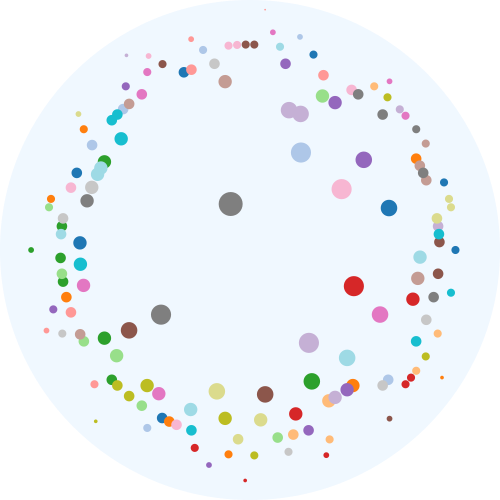

In [71]:
plot_Pdisk_embedding_n(xy_coalescent_p, node_colors=colors, sizes=np.array(N*[0.1]))

In [72]:
t0 = time.time()

mercator.embed(edgelist_path_p+'.txt', output_name=edgelist_path_p, fast_mode=True)

t2_M_fast = time.time()-t0

shutil.copyfile(edgelist_path_p+'.inf_log',edgelist_path_p+'.inf_log'+'.txt') 
shutil.copyfile(edgelist_path_p+'.inf_coord',edgelist_path_p+'.inf_coord'+'.txt') 
coords_tr_p = np.loadtxt(edgelist_path_p+'.inf_coord'+'.txt', usecols=(2,3))

#r_norm_p = coords_tr_p[:,1]/(np.max(coords_tr_p[:,1])+0.2) # normalise radius, +0.2 as it is done in the coalescent embedding alg
r = coords_tr_p[:,1]
r_norm = (r-np.min(r))/(np.max(r)-np.min(r))
x_p, y_p = convert_polar_cartesian(r_norm,coords_tr[:,0])
xy_mercator_p = np.column_stack((x_p,y_p))

R =  1.0


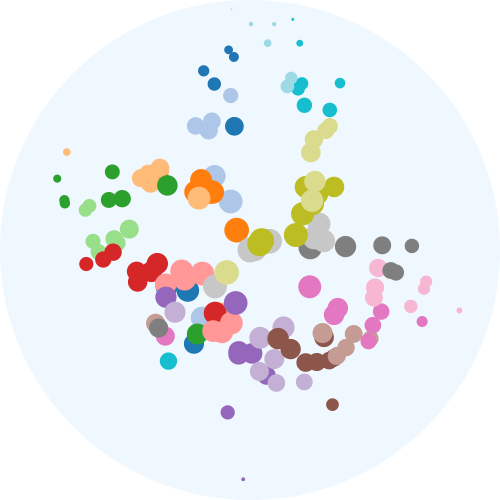

In [73]:
plot_Pdisk_embedding_n(xy_mercator_p, node_colors=colors, sizes=np.array(N*[0.1]))

In [74]:
t0 = time.time()

mercator.embed(edgelist_path_p+'.txt', output_name=edgelist_path_p)

t2_M = time.time()-t0

shutil.copyfile(edgelist_path_p+'.inf_log',edgelist_path_p+'.inf_log'+'.txt') 
shutil.copyfile(edgelist_path_p+'.inf_coord',edgelist_path_p+'.inf_coord'+'.txt') 
coords_tr_p = np.loadtxt(edgelist_path_p+'.inf_coord'+'.txt', usecols=(2,3))

#r_norm_p = coords_tr_p[:,1]/(np.max(coords_tr_p[:,1])+0.2) # normalise radius, +0.2 as it is done in the coalescent embedding alg
r = coords_tr_p[:,1]
r_norm = (r-np.min(r))/(np.max(r)-np.min(r))
x_p, y_p = convert_polar_cartesian(r_norm,coords_tr[:,0])
xy_mercator_p = np.column_stack((x_p,y_p))

R =  1.0


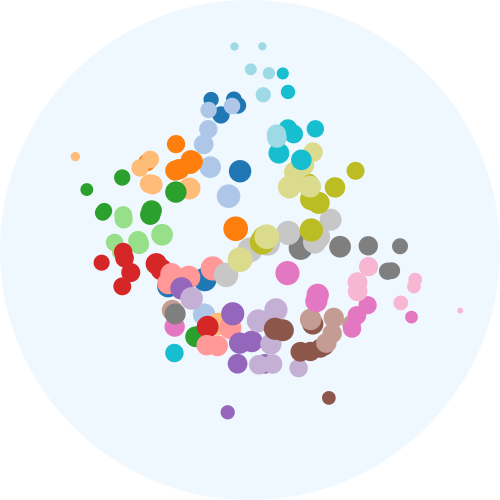

In [75]:
plot_Pdisk_embedding_n(xy_mercator_p, node_colors=colors, sizes=np.array(N*[0.1]))

In [76]:
t0 = time.time()

mercator.embed(edgelist_path_p+'.txt', output_name=edgelist_path_p, inf_coord=edgelist_path+'.inf_coord')

t2_M_ref = time.time()-t0

shutil.copyfile(edgelist_path_p+'.inf_log',edgelist_path_p+'.inf_log'+'.txt') 

shutil.copyfile(edgelist_path_p+'.inf_coord',edgelist_path_p+'.inf_coord'+'.txt') 
coords_tr_p = np.loadtxt(edgelist_path_p+'.inf_coord'+'.txt', usecols=(2,3))

#r_norm_p = coords_tr_p[:,1]/(np.max(coords_tr_p[:,1])+0.2) # normalise radius, +0.2 as it is done in the coalescent embedding alg
r = coords_tr_p[:,1]
r_norm_p = (r-np.min(r))/(np.max(r)-np.min(r))
x_p, y_p = convert_polar_cartesian(r_norm,coords_tr[:,0])
xy_mercator_p = np.column_stack((x_p,y_p))

R =  1.0


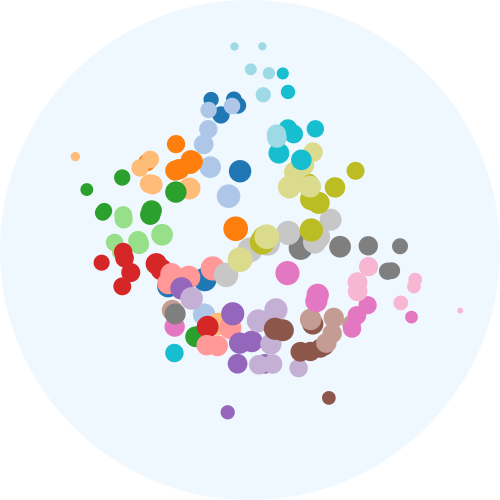

In [77]:
plot_Pdisk_embedding_n(xy_mercator_p, node_colors=colors, sizes=np.array(N*[0.1]))

In [78]:
print('C:',t1_C+t2_C,'M_ref:',t1_M+t2_M_ref,'M:',t1_M+t2_M)

C: 0.0853731632232666 M_ref: 1.8081510066986084 M: 3.753800868988037


### COMPUTE EMBEDDING O+P TIME in function of Network SIZE

- N = 50,100,200,400,500
- plot t_C = t1_C+t_2_C, t_M_ref, t_M vs N


Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()


Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()


Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()


... (6 outputs left out)

Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()


Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()


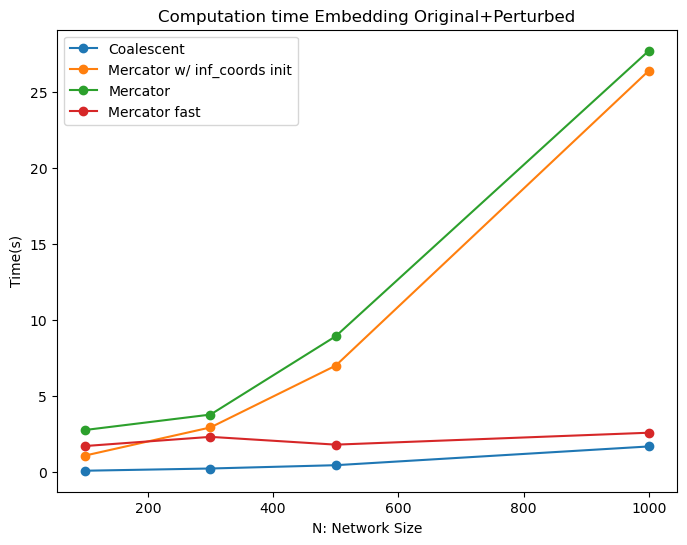

In [85]:
## NETWORK MODEL

model = "WattsStrogatz"
kl = 20 #k lattice
pr = 0.1 #p rewiring

## Embedding parameters COALESCENT

embedding_parameters_dict = {
'preweight':True, 
'laplacian':False, 
'dim_red_method':'ISOMAP', 
'eigen_solver':'dense', 
'n_neighbors':'auto', 
'equi_adj':True, 
'eta_r':1,
'beta_r':0.8,
'order_r':'auto',
'weight_r':None,
'radius_def':True,
'order_sign':1,
'max_r_margin':1e-5,
}
embedding_parameters = np.array(list(embedding_parameters_dict.values()))

## PERTURNBATION parameters

# number of NN to take into account
k = 10

# perturbation magnitude 20-40-60-80/100
mag_arr = np.array([20/100, 40/100, 60/100, 80/100])
mag = mag_arr[0]


# Init variables
N_arr = np.array([100,300,500,1000])
C_time = np.zeros(len(N_arr))
M_time = np.zeros(len(N_arr))
Mr_time = np.zeros(len(N_arr))
Mf_time = np.zeros(len(N_arr))

for i,N in enumerate(N_arr):

    G = nx.watts_strogatz_graph(N,kl,pr)
    degrees = np.array(list(nx.degree(G)))[:,1]
    A = nx.to_numpy_array(G)
    edgelist = from_amatrix_to_edgelist(A)
    edgelist = edgelist[np.where(edgelist[:,2]==1)[0],:].astype('int')
    edgelist_path = '/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/OUTPUT-MEDIA-test-Mercator/Data/edgelist_%s_O' %model
    np.savetxt(edgelist_path+'.txt', edgelist)

    # Coalscent Original
    t0 = time.time()
    dict_xy = coalescent_embedding_2D_fc(G, *embedding_parameters, res_dict=True, normalize_radius=True)
    t1_C = time.time()-t0

    xy_coalescent = np.array(list(dict_xy[0].values()))

    # Mercator Original
    t0 = time.time()
    mercator.embed(edgelist_path+'.txt', output_name=edgelist_path)
    t1_M = time.time()-t0

    shutil.copyfile(edgelist_path+'.inf_log', edgelist_path+'.inf_log'+'.txt')
    shutil.copyfile(edgelist_path+'.inf_coord',edgelist_path+'.inf_coord'+'.txt') 
    coords_tr = np.loadtxt(edgelist_path+'.inf_coord'+'.txt', usecols=(2,3))
    r_norm = coords_tr[:,1]/(np.max(coords_tr[:,1])+0.2) # normalise radius, +0.2 as it is done in the coalescent embedding alg
    x, y = convert_polar_cartesian(r_norm,coords_tr[:,0])
    xy_mercator = np.column_stack((x,y))

    # Mercator Original fast
    t0 = time.time()
    mercator.embed(edgelist_path+'.txt', output_name=edgelist_path, fast_mode=True)
    t1_M_fast = time.time()-t0

    shutil.copyfile(edgelist_path+'.inf_log', edgelist_path+'.inf_log'+'.txt')
    shutil.copyfile(edgelist_path+'.inf_coord',edgelist_path+'.inf_coord'+'.txt') 
    coords_tr = np.loadtxt(edgelist_path+'.inf_coord'+'.txt', usecols=(2,3))
    r_norm = coords_tr[:,1]/(np.max(coords_tr[:,1])+0.2) # normalise radius, +0.2 as it is done in the coalescent embedding alg
    x, y = convert_polar_cartesian(r_norm,coords_tr[:,0])
    xy_mercator_fast = np.column_stack((x,y))

    # Perturbation
    G_p, nodes_p_dict = perturbation_disconnection_NT(G,mag,1,target=[np.random.randint(N)])
    A_p = nx.to_numpy_array(G_p)
    edgelist_p = from_amatrix_to_edgelist(A_p)
    edgelist_p = edgelist_p[np.where(edgelist_p[:,2]==1)[0],:].astype('int')
    edgelist_path_p = '/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/OUTPUT-MEDIA-test-Mercator/Data/edgelist_%s_P%.3f' %(model,mag)
    np.savetxt(edgelist_path_p+'.txt', edgelist_p)

    # Coalescent Perturbed
    t0 = time.time()
    dict_xy_p = coalescent_embedding_2D_fc(G_p, *embedding_parameters, res_dict=True, normalize_radius=True)
    t2_C = time.time()-t0

    xy_coalescent_p = np.array(list(dict_xy_p[0].values()))

    # Mercator Perturbed
    t0 = time.time()
    mercator.embed(edgelist_path_p+'.txt', output_name=edgelist_path_p)
    t2_M = time.time()-t0

    shutil.copyfile(edgelist_path_p+'.inf_log',edgelist_path_p+'.inf_log'+'.txt') 
    shutil.copyfile(edgelist_path_p+'.inf_coord',edgelist_path_p+'.inf_coord'+'.txt') 
    coords_tr_p = np.loadtxt(edgelist_path_p+'.inf_coord'+'.txt', usecols=(2,3))

    r_norm_p = coords_tr_p[:,1]/(np.max(coords_tr_p[:,1])+0.2) # normalise radius, +0.2 as it is done in the coalescent embedding alg
    x_p, y_p = convert_polar_cartesian(r_norm,coords_tr[:,0])
    xy_mercator_p = np.column_stack((x,y))

    # Mercator Perturbed
    t0 = time.time()
    mercator.embed(edgelist_path_p+'.txt', output_name=edgelist_path_p, fast_mode=True)
    t2_M_fast = time.time()-t0

    shutil.copyfile(edgelist_path_p+'.inf_log',edgelist_path_p+'.inf_log'+'.txt') 
    shutil.copyfile(edgelist_path_p+'.inf_coord',edgelist_path_p+'.inf_coord'+'.txt') 
    coords_tr_p = np.loadtxt(edgelist_path_p+'.inf_coord'+'.txt', usecols=(2,3))

    r_norm_p = coords_tr_p[:,1]/(np.max(coords_tr_p[:,1])+0.2) # normalise radius, +0.2 as it is done in the coalescent embedding alg
    x_p, y_p = convert_polar_cartesian(r_norm,coords_tr[:,0])
    xy_mercator_p = np.column_stack((x,y))

    # Mercator Perturbed w/ initial state = Mercator Original
    t0 = time.time()
    mercator.embed(edgelist_path_p+'.txt', output_name=edgelist_path_p, inf_coord=edgelist_path+'.inf_coord')
    t2_M_ref = time.time()-t0

    shutil.copyfile(edgelist_path_p+'.inf_log',edgelist_path_p+'.inf_log'+'.txt') 
    shutil.copyfile(edgelist_path_p+'.inf_coord',edgelist_path_p+'.inf_coord'+'.txt') 
    coords_tr_p = np.loadtxt(edgelist_path_p+'.inf_coord'+'.txt', usecols=(2,3))

    r_norm_p = coords_tr_p[:,1]/(np.max(coords_tr_p[:,1])+0.2) # normalise radius, +0.2 as it is done in the coalescent embedding alg
    x_p, y_p = convert_polar_cartesian(r_norm,coords_tr[:,0])
    xy_mercator_p = np.column_stack((x,y))

    C_time[i] = t1_C+t2_C
    Mr_time[i] = t1_M+t2_M_ref
    M_time[i] = t1_M+t2_M
    Mf_time[i] = t1_M_fast+t2_M_fast

## PLOT
    
plt.figure(figsize=(8,6))
plt.plot(N_arr, C_time, marker='o', label='Coalescent')
plt.plot(N_arr, Mr_time, marker='o', label='Mercator w/ inf_coords init')
plt.plot(N_arr, M_time, marker='o', label='Mercator')
plt.plot(N_arr, Mf_time, marker='o', label='Mercator fast')
plt.xlabel('N: Network Size')
plt.ylabel('Time(s)')
plt.title('Computation time Embedding Original+Perturbed')
plt.legend()
plt.savefig('OUTPUT-MEDIA-test-Mercator/plot_t_vs_N1k_%s_P%.3f.png' %(model,mag))
plt.show()

### COMPUTE EMBEDDING O+P TIME in function of Network SIZE + ALIGNMENT

- N = 50,100,200,400,500
- plot t_C = t1_C+t_2_C, t_M_ref, t_M vs N


In [81]:
def array_to_dict(x, y):
    return {i: [x[i], y[i]] for i in range(len(x))}

Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()


Initialisation of the class done
0.023844003677368164
62.99216082807163


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()


[E] Correction cosh_d <1 :  0.9999999999999997
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <1 :  0.9999999999999997
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999997
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999997
[E] Correction cosh_d <1 :  0.9999999999999997
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correctio

/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()


... (7 outputs left out)

/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()


Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()


0.1363391876220703
212.5299129555172
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999996
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <1 :  0.9999999999999996
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <1 :  0.9999999999999997
[E] Correction cosh_d <1 :  0.9999999999999996
[E] Correction cosh_d <1 :  0.9999999999999996
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <1 :  0.9999999999999998
[E] Correction cosh_d <1 :  0.9999999999999999
[E] Correction cosh_d <

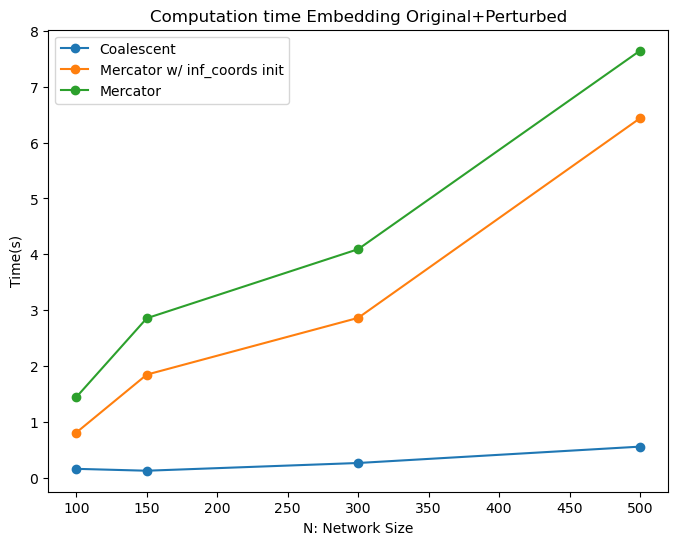

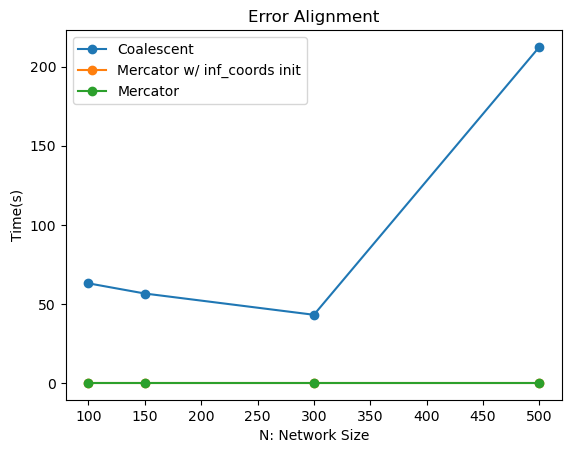

In [82]:
## NETWORK MODEL

model = "WattsStrogatz"
kl = 20 #k lattice
pr = 0.1 #p rewiring

## Embedding parameters COALESCENT

embedding_parameters_dict = {
'preweight':True, 
'laplacian':False, 
'dim_red_method':'ISOMAP', 
'eigen_solver':'dense', 
'n_neighbors':'auto', 
'equi_adj':True, 
'eta_r':1,
'beta_r':0.8,
'order_r':'auto',
'weight_r':None,
'radius_def':True,
'order_sign':1,
'max_r_margin':1e-5,
}
embedding_parameters = np.array(list(embedding_parameters_dict.values()))

## PERTURNBATION parameters

# number of NN to take into account
k = 10

# perturbation magnitude 20-40-60-80/100
mag_arr = np.array([20/100, 40/100, 60/100, 80/100])
mag = mag_arr[0]


# Init variables
N_arr = np.array([100,150,300,500])
C_time = np.zeros(len(N_arr))
C_err = np.zeros(len(N_arr))
M_time = np.zeros(len(N_arr))
M_err = np.zeros(len(N_arr))
Mr_time = np.zeros(len(N_arr))
Mr_err = np.zeros(len(N_arr))

for i,N in enumerate(N_arr):

    G = nx.watts_strogatz_graph(N,kl,pr)
    degrees = np.array(list(nx.degree(G)))[:,1]
    A = nx.to_numpy_array(G)
    edgelist = from_amatrix_to_edgelist(A)
    edgelist = edgelist[np.where(edgelist[:,2]==1)[0],:].astype('int')
    edgelist_path = '/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/OUTPUT-MEDIA-test-Mercator/Data/edgelist_%s_O' %model
    np.savetxt(edgelist_path+'.txt', edgelist)

    # Coalscent Original
    t0 = time.time()
    dict_xy = coalescent_embedding_2D_fc(G, *embedding_parameters, res_dict=True, normalize_radius=True)
    t1_C = time.time()-t0

    xy_coalescent = np.array(list(dict_xy[0].values()))

    # Mercator Original
    t0 = time.time()
    mercator.embed(edgelist_path+'.txt', output_name=edgelist_path)
    t1_M = time.time()-t0

    shutil.copyfile(edgelist_path+'.inf_log', edgelist_path+'.inf_log'+'.txt')
    shutil.copyfile(edgelist_path+'.inf_coord',edgelist_path+'.inf_coord'+'.txt') 
    coords_tr = np.loadtxt(edgelist_path+'.inf_coord'+'.txt', usecols=(2,3))
    r_norm = coords_tr[:,1]/(np.max(coords_tr[:,1])+0.2) # normalise radius, +0.2 as it is done in the coalescent embedding alg
    x, y = convert_polar_cartesian(r_norm,coords_tr[:,0])
    xy_mercator = np.column_stack((x,y))
    dict_xy_mercator = array_to_dict(x,y)

    # Perturbation
    G_p, nodes_p_dict = perturbation_disconnection_NT(G,mag,1,target=[np.random.randint(N)])
    A_p = nx.to_numpy_array(G_p)
    edgelist_p = from_amatrix_to_edgelist(A_p)
    edgelist_p = edgelist_p[np.where(edgelist_p[:,2]==1)[0],:].astype('int')
    edgelist_path_p = '/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/OUTPUT-MEDIA-test-Mercator/Data/edgelist_%s_P%.3f' %(model,mag)
    np.savetxt(edgelist_path_p+'.txt', edgelist_p)

    # Coalescent Perturbed
    t0 = time.time()
    dict_xy_p = coalescent_embedding_2D_fc(G_p, *embedding_parameters, res_dict=True, normalize_radius=True)
    t2_C = time.time()-t0
    
    t0 = time.time()
    dict_xy_p_align, theta, err = rotation_similarity_embedding(dict_xy[0], dict_xy_p[0], 10, 'HYP')
    t2_C_align = time.time()-t0
    print(t2_C_align)
    print(err)
    C_err[i] = err

    xy_coalescent_p = np.array(list(dict_xy_p_align.values()))

    # Mercator Perturbed
    t0 = time.time()
    mercator.embed(edgelist_path_p+'.txt', output_name=edgelist_path_p)
    t2_M = time.time()-t0

    shutil.copyfile(edgelist_path_p+'.inf_log',edgelist_path_p+'.inf_log'+'.txt') 
    shutil.copyfile(edgelist_path_p+'.inf_coord',edgelist_path_p+'.inf_coord'+'.txt') 
    coords_tr_p = np.loadtxt(edgelist_path_p+'.inf_coord'+'.txt', usecols=(2,3))

    r_norm_p = coords_tr_p[:,1]/(np.max(coords_tr_p[:,1])+0.2) # normalise radius, +0.2 as it is done in the coalescent embedding alg
    x_p, y_p = convert_polar_cartesian(r_norm,coords_tr[:,0])
    xy_mercator_p = np.column_stack((x,y))
    dict_xy_mercator_p = array_to_dict(x_p, y_p)

    t0 = time.time()
    dict_xy_mercator_p_align, theta_mercator, err_mercator = rotation_similarity_embedding(dict_xy_mercator, dict_xy_mercator_p, 10, 'HYP')
    t2_M_align = time.time()-t0
    print(t2_M_align)
    print(err_mercator)
    M_err[i] = err_mercator

    # Mercator Perturbed w/ initial state = Mercator Original
    t0 = time.time()
    mercator.embed(edgelist_path_p+'.txt', output_name=edgelist_path_p, inf_coord=edgelist_path+'.inf_coord')
    t2_M_ref = time.time()-t0

    shutil.copyfile(edgelist_path_p+'.inf_log',edgelist_path_p+'.inf_log'+'.txt') 
    shutil.copyfile(edgelist_path_p+'.inf_coord',edgelist_path_p+'.inf_coord'+'.txt') 
    coords_tr_p = np.loadtxt(edgelist_path_p+'.inf_coord'+'.txt', usecols=(2,3))

    r_norm_p = coords_tr_p[:,1]/(np.max(coords_tr_p[:,1])+0.2) # normalise radius, +0.2 as it is done in the coalescent embedding alg
    x_p, y_p = convert_polar_cartesian(r_norm,coords_tr[:,0])
    xy_mercator_p = np.column_stack((x,y))
    dict_xy_mercator_p = array_to_dict(x_p, y_p)

    t0 = time.time()
    dict_xy_mercator_p_align, theta_mercator_ref, err_mercator_ref = rotation_similarity_embedding(dict_xy_mercator, dict_xy_mercator_p, 10, 'HYP')
    t2_M_ref_align = time.time()-t0
    print(t2_M_ref_align)
    print(err_mercator_ref)
    Mr_err[i] = err_mercator_ref

    C_time[i] = t1_C+t2_C+t2_C_align
    Mr_time[i] = t1_M+t2_M_ref+t2_M_ref_align
    M_time[i] = t1_M+t2_M+t2_M_align

## PLOT
    
plt.figure(figsize=(8,6))
plt.plot(N_arr, C_time, marker='o', label='Coalescent')
plt.plot(N_arr, Mr_time, marker='o', label='Mercator w/ inf_coords init')
plt.plot(N_arr, M_time, marker='o', label='Mercator')
plt.xlabel('N: Network Size')
plt.ylabel('Time(s)')
plt.title('Computation time Embedding Original+Perturbed')
plt.legend()
plt.savefig('OUTPUT-MEDIA-test-Mercator/plot_t_vs_N_%s_P%.3f_align.png' %(model,mag))
plt.show()

plt.figure()
plt.plot(N_arr, C_err, marker='o', label='Coalescent')
plt.plot(N_arr, Mr_err, marker='o', label='Mercator w/ inf_coords init')
plt.plot(N_arr, M_err, marker='o', label='Mercator')
plt.xlabel('N: Network Size')
plt.ylabel('Time(s)')
plt.title('Error Alignment')
plt.legend()
plt.savefig('OUTPUT-MEDIA-test-Mercator/plot_err_vs_N_%s_P%.3f_align.png' %(model,mag))
plt.show()

In [83]:
[np.sqrt(np.sum(np.power(dict_xy_mercator[i],2))) for i in range(N)]

[0.8541198417548487,
 0.8666276414396449,
 0.8752307741790227,
 0.8934508378630471,
 0.8936785564954488,
 0.9129458685793316,
 0.8973593644463027,
 0.9241246663021453,
 0.8806625711620727,
 0.9462275256505098,
 0.8991257920298478,
 0.8898922517770416,
 0.8326654015631533,
 0.8825975362645139,
 0.8241561866778168,
 0.8073371715287383,
 0.8789012897623106,
 0.8192209964298349,
 0.835274516741179,
 0.8666250683477533,
 0.8820417484159401,
 0.8483342446367116,
 0.8263407416937377,
 0.883442796950886,
 0.8745643433791129,
 0.8999942105432439,
 0.8829706345887877,
 0.8396281882216718,
 0.8676748898395034,
 0.8532025344955132,
 0.8829346113023061,
 0.8796243285838345,
 0.8478080473448908,
 0.8815515744106011,
 0.8652433180019943,
 0.8893943584960277,
 0.8814692354700717,
 0.8383274902704962,
 0.8604316361648066,
 0.8827197581293622,
 0.8418654916213695,
 0.8698452928500208,
 0.8628542021806954,
 0.8910475700363448,
 0.8778501817246148,
 0.8517024219227428,
 0.8601048534945805,
 0.852217040301